# **트랜스포머와 LLM**


---



# **1. Attention: Q · K · V**

| Lab |주제 | 연결 |
|---|---|---|
| 1-0 |  어텐션 = '부드러운 사전 검색' | 9차시 Bahdanau 어텐션 |
| 1-1 | 3토큰 셀프 어텐션 손계산 | Vaswani et al. (2017) 식 (1) |
| 1-2 | 왜 √dₖ로 나누는가? — 분산 실험 | |
| 1-3 | 패딩 마스크와 인과(causal) 마스크 | 3교시 GPT |
| 1-4 | 멀티헤드 어텐션 직접 구현 = `nn.MultiheadAttention` = `F.scaled_dot_product_attention` | 교재 7_4 |
| 1-5 |  시퀀스 길이 T를 늘리면? — O(T²) 측정 | 9차시 RNN의 귀환 |

In [1]:
%pip install -q koreanize-matplotlib

In [2]:
import math, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import koreanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False
import os; os.makedirs("figs", exist_ok=True)
torch.manual_seed(0); np.random.seed(0)
print("torch", torch.__version__)

torch 2.11.0+cpu


---
## **1-0. 어텐션** = '부드러운 사전(dict) 검색'
파이썬 dict는 **키가 정확히 같을 때만** 값을 꺼낸다. 어텐션은 **모든 키와 비슷한 정도(유사도)를 재서 값들을 섞는다.**

In [3]:
menu = {"짜장면": 7000, "짬뽕": 8000, "탕수육": 15000}
print("하드 검색:", menu["짬뽕"])               # 정확히 일치하는 키 하나

# 부드러운 검색: 질의(query)와 각 키의 유사도 → softmax → 값의 가중합
keys   = np.array([[1.0, 0.0], [0.9, 0.3], [0.0, 1.0]])   # 짜장면, 짬뽕, 탕수육의 '특징'
values = np.array([7000, 8000, 15000])
query  = np.array([1.0, 0.2])                              # "면 요리 비슷한 거"
scores = keys @ query                                      # 내적 = 유사도
weights = np.exp(scores) / np.exp(scores).sum()            # softmax
print("유사도:", scores.round(2), "→ 가중치:", weights.round(3))
print("부드러운 검색 결과(가중 평균 가격):", round(float(weights @ values)))

하드 검색: 8000
유사도: [1.   0.96 0.2 ] → 가중치: [0.415 0.399 0.186]
부드러운 검색 결과(가중 평균 가격): 8890


---
## **1-1. 3토큰 셀프 어텐션 손계산**
$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\dfrac{QK^\top}{\sqrt{d_k}}\right)V$, 이때 $Q = XW_Q,\ K = XW_K,\ V = XW_V$ — **세 값 모두 같은 입력 X에서** 나온다 (그래서 '셀프')

In [4]:
tokens = ["나는", "사과를", "먹었다"]
X = torch.tensor([[1., 0., 1., 0.],      # 나는
                  [0., 2., 0., 2.],      # 사과를
                  [1., 1., 1., 1.]])     # 먹었다   (T=3, d_model=4)
W_Q = torch.tensor([[1., 0.], [0., 1.], [1., 0.], [0., 1.]])
W_K = torch.tensor([[0., 1.], [1., 0.], [0., 1.], [1., 0.]])
W_V = torch.tensor([[1., 1.], [0., 1.], [1., 0.], [0., 0.]])

Q, K, V = X @ W_Q, X @ W_K, X @ W_V            # (3, 2)
d_k = Q.shape[-1]
scores = Q @ K.T                                # ① 유사도 점수 (3×3)
scaled = scores / math.sqrt(d_k)                # ② 스케일링
A = torch.softmax(scaled, dim=-1)               # ③ 행마다 확률분포 (합=1)
out = A @ V                                     # ④ 값의 가중합
for name, M in [("Q", Q), ("K", K), ("V", V), ("QKᵀ", scores), ("÷√dₖ", scaled), ("softmax", A), ("출력", out)]:
    print(f"{name}:\n{M.numpy().round(3)}\n")
print("행 합:", A.sum(-1).numpy())

Q:
[[2. 0.]
 [0. 4.]
 [2. 2.]]

K:
[[0. 2.]
 [4. 0.]
 [2. 2.]]

V:
[[2. 1.]
 [0. 2.]
 [2. 2.]]

QKᵀ:
[[0. 8. 4.]
 [8. 0. 8.]
 [4. 8. 8.]]

÷√dₖ:
[[0.    5.657 2.828]
 [5.657 0.    5.657]
 [2.828 5.657 5.657]]

softmax:
[[0.003 0.941 0.056]
 [0.499 0.002 0.499]
 [0.029 0.486 0.486]]

출력:
[[0.118 1.997]
 [1.997 1.501]
 [1.029 1.971]]

행 합: [0.9999999  1.         0.99999994]


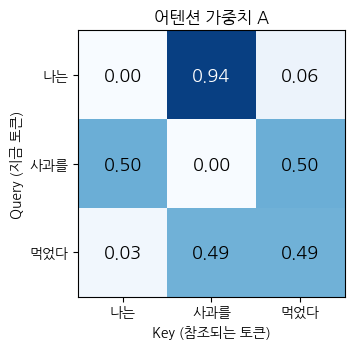

In [5]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{A[i,j]:.2f}", ha="center", va="center", fontsize=13, color="white" if A[i, j] > .5 else "black")
ax.set_xticks(range(3), tokens); ax.set_yticks(range(3), tokens)
ax.set_xlabel("Key (참조되는 토큰)"); ax.set_ylabel("Query (지금 토큰)"); ax.set_title("어텐션 가중치 A")
plt.tight_layout(); plt.savefig("figs/attn_hand.png", dpi=160); plt.show()

**🎯 미션**: `W_Q`를 바꿔 '먹었다'가 '사과를'에 가장 집중하도록 만들어 보자.

In [11]:
# `W_Q`를 바꿔 '먹었다'가 '사과를'에 가장 집중하도록 만들어 보자.
import math
import torch

tokens = ["나는", "사과를", "먹었다"]
X = torch.tensor([[1., 0., 1., 0.],      # 나는
                  [0., 2., 0., 2.],      # 사과를
                  [1., 1., 1., 1.]])     # 먹었다   (T=3, d_model=4)

# W_Q를 변경하여 '먹었다'(X[2])의 Query가 '사과를'(K[1] = [4, 0])에 집중하도록 설정
# X[2] = [1, 1, 1, 1]과 곱해져서 Query가 [4, 0]에 가까운 값이 나오도록 설계합니다.
W_Q = torch.tensor([
    [0., 0.],
    [0., 0.],
    [4., 0.],
    [0., 0.]
])

W_K = torch.tensor([[0., 1.], [1., 0.], [0., 1.], [1., 0.]])
W_V = torch.tensor([[1., 1.], [0., 1.], [1., 0.], [0., 0.]])

Q, K, V = X @ W_Q, X @ W_K, X @ W_V            # (3, 2)
d_k = Q.shape[-1]
scores = Q @ K.T                                # ① 유사도 점수 (3×3)
scaled = scores / math.sqrt(d_k)
A = torch.softmax(scaled, dim=-1)               # ③ 행마다 확률분포

for name, M in [("Q", Q), ("K", K), ("softmax (A)", A)]:
    print(f"{name}:\n{M.numpy().round(3)}\n")

Q:
[[4. 0.]
 [0. 0.]
 [4. 0.]]

K:
[[0. 2.]
 [4. 0.]
 [2. 2.]]

softmax (A):
[[0.    0.997 0.003]
 [0.333 0.333 0.333]
 [0.    0.997 0.003]]



---
## **1-2. 왜 √dₖ로 나누는가?**
q, k의 각 원소가 평균 0·분산 1이면 $q\cdot k=\sum_{i=1}^{d_k} q_i k_i$ 의 분산은 $d_k$ → 차원이 클수록 점수가 커지고 softmax가 한 칸에 몰린다(기울기 ≈ 0).

In [12]:
rows = []
for d in [4, 16, 64, 256, 1024]:
    q = torch.randn(10000, d)
    k = torch.randn(10000, d)
    dot = (q * k).sum(-1)
    # 키 8개 중에서 softmax를 했을 때 가장 큰 가중치의 평균 (1에 가까울수록 '한 칸 몰빵')
    s = torch.randn(2000, 8, d) @ torch.randn(2000, d, 1)
    p_raw = torch.softmax(s.squeeze(-1), -1).max(-1).values.mean().item()
    p_scaled = torch.softmax(s.squeeze(-1) / math.sqrt(d), -1).max(-1).values.mean().item()
    rows.append([d, round(dot.var().item(), 1), round(p_raw, 3), round(p_scaled, 3)])
import pandas as pd
scale_df = pd.DataFrame(rows, columns=["d_k", "q·k 분산", "최대 가중치(스케일 X)", "최대 가중치(÷√dₖ)"])
scale_df.to_csv("scale_experiment.csv", index=False)
scale_df

,d_k,q·k 분산,최대 가중치(스케일 X),최대 가중치(÷√dₖ)
0,4,3.9,0.530,0.345
1,16,16.2,0.752,0.358
2,64,64.1,0.869,0.359
3,256,263.3,0.940,0.362
4,1024,1039.9,0.971,0.361


**관찰**: 분산이 정확히 $d_k$로 커진다. 나누지 않으면 $d_k=1024$에서 거의 한 키에만 집중(최대 가중치 ≈ 1) → softmax 기울기 소실. $\sqrt{d_k}$로 나누면 분산이 1로 돌아와 차원과 무관하게 일정하다.

---
## **1-3. 마스크**: 보면 안 되는 곳을 −∞로
- **패딩 마스크**: 길이를 맞추려고 넣은 `<pad>`는 보지 않는다 (9차시 `pack_padded_sequence`의 역할)
- **인과 마스크**: 생성 모델은 **미래 토큰을 보면 안 된다** (컨닝 방지) → GPT의 핵심

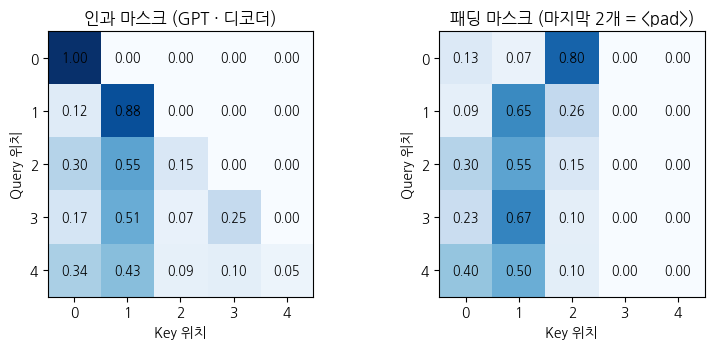

직접 구현 = SDPA(is_causal=True)? True


In [7]:
T = 5
scores = torch.randn(T, T)
causal = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)   # 대각선 위 = 미래
pad = torch.tensor([False, False, False, True, True])                 # 마지막 2개는 <pad>
A_causal = torch.softmax(scores.masked_fill(causal, float("-inf")), -1)
A_pad = torch.softmax(scores.masked_fill(pad, float("-inf")), -1)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, M, t in zip(axes, [A_causal, A_pad], ["인과 마스크 (GPT · 디코더)", "패딩 마스크 (마지막 2개 = <pad>)"]):
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for i in range(T):
        for j in range(T):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(t); ax.set_xlabel("Key 위치"); ax.set_ylabel("Query 위치")
plt.tight_layout(); plt.savefig("figs/masks.png", dpi=160); plt.show()

# PyTorch 실무 API는 is_causal=True 한 줄이면 된다
q = k = v = torch.randn(1, 1, T, 8)
manual = torch.softmax((q @ k.transpose(-2, -1) / math.sqrt(8)).masked_fill(causal, float("-inf")), -1) @ v
fast = F.scaled_dot_product_attention(q, k, v, is_causal=True)
print("직접 구현 = SDPA(is_causal=True)?", torch.allclose(manual, fast, atol=1e-6))

---
## **1-4. 멀티헤드 어텐션**: 직접 구현 = PyTorch 표준
$\text{MultiHead}(X) = \text{Concat}(\text{head}_1, …, \text{head}_h)W_O,\quad \text{head}_i = \text{Attention}(XW_Q^i, XW_K^i, XW_V^i)$

In [8]:
class MultiHeadSelfAttention(nn.Module):
    """교재 7-2 흐름을 실무 형태로: QKV를 한 번의 Linear로 계산하고 SDPA 사용"""
    def __init__(self, d_model, n_heads, causal=False):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_head, self.causal = n_heads, d_model // n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model)     # W_Q, W_K, W_V를 하나로 묶음 (GPT-2 c_attn과 같은 방식)
        self.out = nn.Linear(d_model, d_model)         # W_O
    def forward(self, x, use_sdpa=True):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=-1)                                   # 각 (B, T, C)
        q, k, v = (t.view(B, T, self.h, self.d_head).transpose(1, 2) for t in (q, k, v))   # (B, h, T, d_head)
        if use_sdpa:                                                             # 실무: 최적화 커널 (FlashAttention 등)
            y = F.scaled_dot_product_attention(q, k, v, is_causal=self.causal)
        else:                                                                    # 교육용: 식 그대로
            att = q @ k.transpose(-2, -1) / math.sqrt(self.d_head)               # (B, h, T, T)
            if self.causal:
                att = att.masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), float("-inf"))
            y = torch.softmax(att, -1) @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)                         # 헤드 이어붙이기
        return self.out(y)

B, T, C, h = 2, 10, 64, 8
x = torch.randn(B, T, C)
mha = MultiHeadSelfAttention(C, h)
y1, y2 = mha(x, use_sdpa=False), mha(x, use_sdpa=True)

# nn.MultiheadAttention에 같은 가중치를 복사해 비교
ref = nn.MultiheadAttention(C, h, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(mha.qkv.weight); ref.in_proj_bias.copy_(mha.qkv.bias)
    ref.out_proj.weight.copy_(mha.out.weight); ref.out_proj.bias.copy_(mha.out.bias)
y3, _ = ref(x, x, x)
print("직접 구현 = SDPA 버전?", torch.allclose(y1, y2, atol=1e-5))
print("직접 구현 = nn.MultiheadAttention?", torch.allclose(y1, y3, atol=1e-5))
print("파라미터 수:", sum(p.numel() for p in mha.parameters()), "= 4·C² + 4·C =", 4 * C * C + 4 * C)

직접 구현 = SDPA 버전? True
직접 구현 = nn.MultiheadAttention? True
파라미터 수: 16640 = 4·C² + 4·C = 16640


In [9]:
shape_rows = [["입력 x", "(B, T, C)", str(tuple(x.shape))],
              ["qkv(x) → split", "3 × (B, T, C)", f"3 × {(B, T, C)}"],
              ["헤드로 나누기 view+transpose", "(B, h, T, C/h)", str((B, h, T, C // h))],
              ["점수 QKᵀ", "(B, h, T, T)", str((B, h, T, T))],
              ["가중합 AV", "(B, h, T, C/h)", str((B, h, T, C // h))],
              ["헤드 합치기 → W_O", "(B, T, C)", str(tuple(y1.shape))]]
shape_df = pd.DataFrame(shape_rows, columns=["단계", "모양(기호)", "이번 예 (B=2, T=10, C=64, h=8)"])
shape_df.to_csv("mha_shapes.csv", index=False)
shape_df

,단계,모양(기호),"이번 예 (B=2, T=10, C=64, h=8)"
0,입력 x,"(B, T, C)","(2, 10, 64)"
1,qkv(x) → split,"3 × (B, T, C)","3 × (2, 10, 64)"
2,헤드로 나누기 view+transpose,"(B, h, T, C/h)","(2, 8, 10, 8)"
3,점수 QKᵀ,"(B, h, T, T)","(2, 8, 10, 10)"
4,가중합 AV,"(B, h, T, C/h)","(2, 8, 10, 8)"
5,헤드 합치기 → W_O,"(B, T, C)","(2, 10, 64)"


---
## **1-5. 길이 T를 2배로 늘리면 비용은?** — O(T²)

In [10]:
rows = []
mha_c = MultiHeadSelfAttention(256, 8, causal=True).eval()
for T in [256, 512, 1024, 2048]:
    x = torch.randn(1, T, 256)
    with torch.no_grad():
        for use in [False, True]:
            mha_c(x, use_sdpa=use)                                  # 워밍업
            t0 = time.perf_counter()
            for _ in range(3):
                mha_c(x, use_sdpa=use)
            rows.append([T, "직접 구현" if not use else "SDPA", (time.perf_counter() - t0) / 3 * 1000])
    rows[-1].append(T * T * 8 * 4 / 2**20)                          # 점수 행렬 메모리 (MB, float32)
cost = pd.DataFrame(rows, columns=["T", "방식", "시간(ms)", "점수행렬(MB)"]).pivot_table(index="T", columns="방식", values="시간(ms)").round(1)
cost["점수행렬 메모리(MB)"] = [T * T * 8 * 4 / 2**20 for T in cost.index]
cost.to_csv("attn_cost.csv")
cost

방식,SDPA,직접 구현,점수행렬 메모리(MB)
T,,,
256,8.5,11.6,2.0
512,30.6,49.3,8.0
1024,61.2,234.1,32.0
2048,394.9,1132.1,128.0


**관찰**: T가 2배 → 점수 행렬은 4배. 그래서 긴 문맥 LLM은 (1) FlashAttention 같은 메모리 절약 커널, (2) GQA로 KV 줄이기, (3) 9차시의 선형 순환 층과 섞은 하이브리드 구조를 쓴다.

## **정리**
| 개념 | 한 줄 요약 |
|---|---|
| Q · K · V | 찾는 것 · 가진 것의 특징 · 실제 내용 |
| softmax(QKᵀ/√dₖ)V | 유사도 → 확률 → 가중합 |
| √dₖ | 내적의 분산을 1로 되돌려 softmax 포화 방지 |
| 마스크 | 패딩·미래를 −∞로 → 확률 0 |
| 멀티헤드 | 여러 관점의 어텐션을 병렬로, 파라미터 4C² |